# Лабораторная работа 11

Тема: **Автоэнкодер для изображений MNIST в PyTorch**  
Формат: практическая работа с обязательными собственными комментариями и экспериментами.

> Этот ноутбук специально оформлен так, чтобы **нельзя было сделать отчёт простым копированием чужого кода или ответов генеративной модели**.  
> Каркас кода даёт вам рабочий пример, но оцениваться будут **ваши** настройки, эксперименты и живые текстовые объяснения.


## 1. Ваши ожидания от автоэнкодера

Перед запуском кода сформулируйте текущие ожидания (6–10 предложений):

1. Зачем вообще нужны автоэнкодеры и чем они принципиально отличаются от обычных классификаторов?
2. Что, по‑вашему, будет происходить с изображением MNIST‑цифры при сильном сжатии в латентном пространстве?  
3. Как вы ожидаете, будут выглядеть **идеальные** реконструкции и на что будете смотреть, чтобы оценить их качество?

In [16]:
intro_text = """
1. Автоэнкодеры нужны для выделения признаков и распределния их по кластерам. 
В задачах классификации количество классов строго ограничего, а у автоэнкодеров оно задано размерностью латентного пространства.
2. При сжатии в латентном пространстве кластеры сильно пересекаются и накладываются друг на друга. 
Это приводит к тому, что при восстановлении мы получаем менее четкие изображения, но при генерации получаем более четкие результаты.
3. Идеальные реконструкции будут почти в точности повторять исходные изображения. Оценить качество можно путем сравнения исходных данных и реконструированных.
""" 
print(intro_text)


1. Автоэнкодеры нужны для выделения признаков и распределния их по кластерам. 
В задачах классификации количество классов строго ограничего, а у автоэнкодеров оно задано размерностью латентного пространства.
2. При сжатии в латентном пространстве кластеры сильно пересекаются и накладываются друг на друга. 
Это приводит к тому, что при восстановлении мы получаем менее четкие изображения, но при генерации получаем более четкие результаты.
3. Идеальные реконструкции будут почти в точности повторять исходные изображения. Оценить качество можно путем сравнения исходных данных и реконструированных.



## 2. Импорт библиотек и настройка среды


In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

MY_SEED = 1  # при своих экспериментах можете поменять, но зафиксируйте в отчёте
torch.manual_seed(MY_SEED)
np.random.seed(MY_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)
print("MY_SEED =", MY_SEED)

Устройство: cpu
MY_SEED = 1


## 3. Данные MNIST и DataLoader

Используем стандартный MNIST (28×28, оттенки серого).  
Автоэнкодер будет учиться восстанавливать картинку **самой себя**.


In [2]:
batch_size = 32

transform = transforms.Compose([
    transforms.ToTensor()
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform,
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print("Размер train:", len(train_dataset))
print("Размер test :", len(test_dataset))

Размер train: 60000
Размер test : 10000


Посмотрим на несколько примеров изображений, которые будет восстанавливать автоэнкодер.


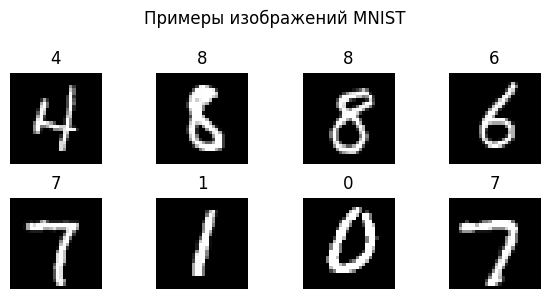

In [3]:
images, labels = next(iter(train_loader))
plt.figure(figsize=(6, 3))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].squeeze(0), cmap="gray")
    plt.title(str(labels[i].item()))
    plt.axis("off")
plt.suptitle("Примеры изображений MNIST")
plt.tight_layout()
plt.show()

### Краткий комментарий по данным

Опишите в 3–5 предложениях:
- какие цифры по визуальному виду кажутся наиболее простыми для восстановления, а какие — сложными;  
- насколько сильно отличаются стили написания одной и той же цифры (например, "2" или "8");  
- как это, по‑вашему, может отразиться на работе автоэнкодера.


In [17]:
data_comment = """
1. Как мне кажется, цифры, непохожие на остальные,например 1 или 6 будет проще восстановить, так как их кластеры будут отделены от других.
Похожие же друг на друга цифры, например 3 и 8, будет сложнее восстановить, так как их кластеры будут пересекаться.
2. Есть как и похожие по написанию, так и непохожие.
3. Я ожидаю, что кластеры похожих цифр будут располагаться близко друг к другу, может даже перекрывать друг друга, а непохожих - максимально удаленно.
"""
print(data_comment)


1. Как мне кажется, цифры, непохожие на остальные,например 1 или 6 будет проще восстановить, так как их кластеры будут отделены от других.
Похожие же друг на друга цифры, например 3 и 8, будет сложнее восстановить, так как их кластеры будут пересекаться.
2. Есть как и похожие по написанию, так и непохожие.
3. Я ожидаю, что кластеры похожих цифр будут располагаться близко друг к другу, может даже перекрывать друг друга, а непохожих - максимально удаленно.



## 4. Архитектура простого полносвязного автоэнкодера

Будем работать с векторизованным изображением размерности 784 (28×28).  
Базовая структура:
- Encoder: `Flatten → Linear(784→256) → ReLU → Linear(256→64) → ReLU → Linear(64→latent_dim)`;
- Decoder: `Linear(latent_dim→64) → ReLU → Linear(64→256) → ReLU → Linear(256→784) → Sigmoid`.

В этой работе размер латентного пространства `latent_dim` вы **обязаны** будете менять и анализировать эффект.


In [4]:
latent_dim = 64  # базовое значение; в отчёте попробуйте хотя бы ещё два

class FCN_Autoencoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 28 * 28),
            nn.Sigmoid(),  # пиксели в 
        )

    def forward(self, x):
        z = self.encoder(x)
        out = self.decoder(z)
        out = out.view(-1, 1, 28, 28)
        return out, z

model = FCN_Autoencoder(latent_dim=latent_dim).to(device)
print(model)

FCN_Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)


### Обсуждение архитектуры

Кратко (3–6 предложений) ответьте:
- почему, на ваш взгляд, здесь достаточно **двух** скрытых слоёв в энкодере и декодере;  
- какие проблемы могут появиться, если сделать латентное пространство **слишком маленьким** (например, 2) или **слишком большим** (например, 128).


In [18]:
arch_comment = """
1. Так как изображения небольшие и черно-белые, то для их обработки не нужна слишком большая сеть.
2. Если пространство будет слишком маленьким, то классы будут находится близко друг к другу и это усложнит восстановление, но упростит генрацию.
Если же пространство будет слишком большим, то классы будут располагаться далеко друг от друга, что упростит восстановление, но из-за этого генерация станет хуже.
"""
print(arch_comment)


1. Так как изображения небольшие и черно-белые, то для их обработки не нужна слишком большая сеть.
2. Если пространство будет слишком маленьким, то классы будут находится близко друг к другу и это усложнит восстановление, но упростит генрацию.
Если же пространство будет слишком большим, то классы будут располагаться далеко друг от друга, что упростит восстановление, но из-за этого генерация станет хуже.



## 5. Функция потерь, оптимизатор и цикл обучения

Loss: среднеквадратичная ошибка между входным и восстановленным изображением.  
Оптимизатор: Adam с умеренным шагом.


In [5]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def train_one_epoch(model, dataloader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0
    total = 0
    for images, _ in dataloader:
        images = images.to(device)

        optimizer.zero_grad()
        outputs, _ = model(images)
        loss = criterion(outputs, images)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        total += images.size(0)

    return total_loss / total

def evaluate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    total = 0
    with torch.no_grad():
        for images, _ in dataloader:
            images = images.to(device)
            outputs, _ = model(images)
            loss = criterion(outputs, images)
            total_loss += loss.item() * images.size(0)
            total += images.size(0)
    return total_loss / total

print("Функции train_one_epoch и evaluate определены.")

Функции train_one_epoch и evaluate определены.


In [6]:
num_epochs = 15  # в отчёте попробуйте другое число эпох и сравните
history = {"train_loss": [], "test_loss": []}

for epoch in range(1, num_epochs + 1):
    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    test_loss = evaluate(model, test_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["test_loss"].append(test_loss)

    print(f"Эпоха {epoch}/{num_epochs}: train_loss={train_loss:.4f}, test_loss={test_loss:.4f}")

Эпоха 1/15: train_loss=0.0330, test_loss=0.0191
Эпоха 2/15: train_loss=0.0163, test_loss=0.0135
Эпоха 3/15: train_loss=0.0125, test_loss=0.0111
Эпоха 4/15: train_loss=0.0105, test_loss=0.0097
Эпоха 5/15: train_loss=0.0093, test_loss=0.0087
Эпоха 6/15: train_loss=0.0085, test_loss=0.0084
Эпоха 7/15: train_loss=0.0079, test_loss=0.0076
Эпоха 8/15: train_loss=0.0075, test_loss=0.0073
Эпоха 9/15: train_loss=0.0071, test_loss=0.0070
Эпоха 10/15: train_loss=0.0068, test_loss=0.0066
Эпоха 11/15: train_loss=0.0065, test_loss=0.0065
Эпоха 12/15: train_loss=0.0063, test_loss=0.0062
Эпоха 13/15: train_loss=0.0061, test_loss=0.0061
Эпоха 14/15: train_loss=0.0059, test_loss=0.0059
Эпоха 15/15: train_loss=0.0058, test_loss=0.0058


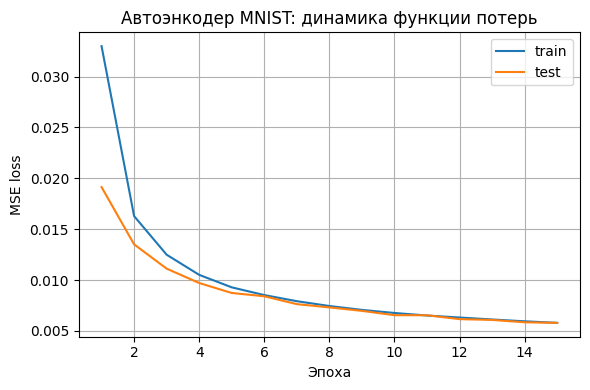

Финальные значения: train_loss=0.0058, test_loss=0.0058


In [7]:
epochs = np.arange(1, num_epochs + 1)

plt.figure(figsize=(6, 4))
plt.plot(epochs, history["train_loss"], label="train")
plt.plot(epochs, history["test_loss"], label="test")
plt.xlabel("Эпоха")
plt.ylabel("MSE loss")
plt.title("Автоэнкодер MNIST: динамика функции потерь")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Финальные значения: train_loss={history['train_loss'][-1]:.4f}, test_loss={history['test_loss'][-1]:.4f}")

### Анализ кривых обучения

Опишите (6–8 предложений):
- по какой траектории меняются train/test loss и сходятся ли они к близким значениям;  
- есть ли признаки переобучения (train сильно ниже test к концу);  
- каких значений loss вы ожидали **до** опыта и совпало ли это с результатами.


In [19]:
training_comment = """
1. train и test loss изменяются, при этом достаточно стремительно, примерно по -экспоненциальной траектории. 
На протяжении всех эпох кривые располагаются достаточно близко друг к другу, сходясь к последним эпохам.
2. Так как train и test loss достаточно близки, то можно говорить, что переобучения нет.
3. Я ожидал значения ~0.05, но увидел >0.01, что меня достаточно удивило
"""
print(training_comment)


1. train и test loss изменяются, при этом достаточно стремительно, примерно по -экспоненциальной траектории. 
На протяжении всех эпох кривые располагаются достаточно близко друг к другу, сходясь к последним эпохам.
2. Так как train и test loss достаточно близки, то можно говорить, что переобучения нет.
3. Я ожидал значения ~0.05, но увидел >0.01, что меня достаточно удивило



## 6. Визуализация реконструкций

Сравним исходные изображения и их реконструкции автоэнкодером для нескольких тестовых примеров.


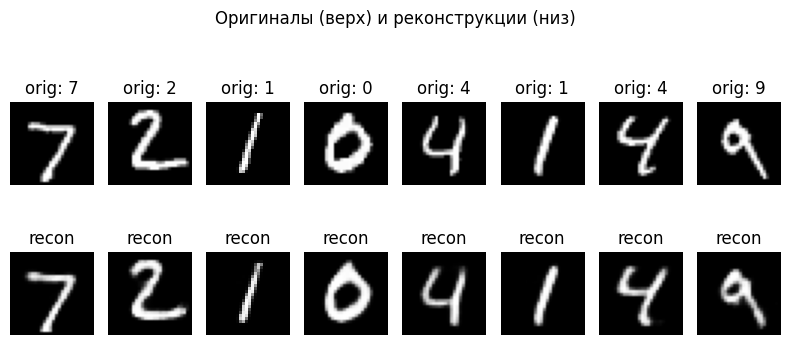

In [9]:
model.eval()
images, labels = next(iter(test_loader))
images = images.to(device)
with torch.no_grad():
    reconstructions, _ = model(images)

images = images.cpu()
reconstructions = reconstructions.cpu()

n = 8
plt.figure(figsize=(8, 4))
for i in range(n):
    # оригинал
    plt.subplot(2, n, i + 1)
    plt.imshow(images[i].squeeze(0), cmap="gray")
    plt.title(f"orig: {labels[i].item()}")
    plt.axis("off")
    # реконструкция
    plt.subplot(2, n, n + i + 1)
    plt.imshow(reconstructions[i].squeeze(0), cmap="gray")
    plt.title("recon")
    plt.axis("off")
plt.suptitle("Оригиналы (верх) и реконструкции (низ)")
plt.tight_layout()
plt.show()

### Качественная оценка реконструкций

Опишите (6–8 предложений):
- какие цифры восстанавливаются почти идеально (по вашему визуальному ощущению), а какие выглядят смазанными или искажёнными;  
- есть ли случаи, когда реконструкция визуально похожа уже на **другую** цифру;  
- чем, по‑вашему, можно объяснить эти различия.


In [20]:
recon_comment = """
1. По-моему мнению, все цифры при латентном простанстве 16, восстанавливаются достаточно хорошо. Сильных смазанностей нет.
2. Визуально, реконструкции 4 и 9 выглядят похожими друг на друга. 
3.Это оправдано тем, что цифры похожи друг на друга.
"""
print(recon_comment)


1. По-моему мнению, все цифры при латентном простанстве 16, восстанавливаются достаточно хорошо. Сильных смазанностей нет.
2. Визуально, реконструкции 4 и 9 выглядят похожими друг на друга. 
3.Это оправдано тем, что цифры похожи друг на друга.



## 7. Латентное пространство: PCA‑проекция в 2D

Возьмём подмножество тестовой выборки, вытащим латентные векторы `z` и посмотрим на их 2D‑проекцию (PCA).  
Цель: увидеть, группируются ли разные цифры в отдельные кластеры.


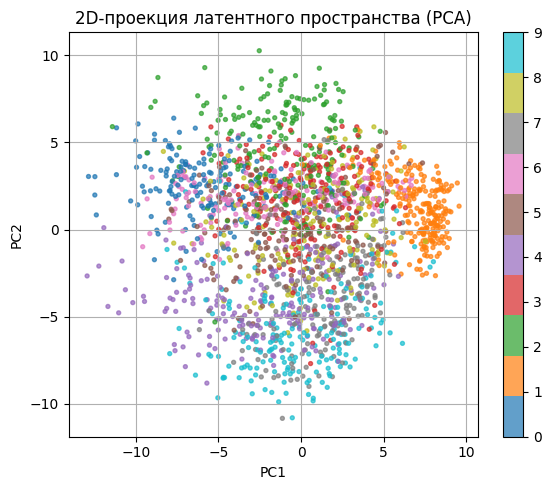

In [11]:
from sklearn.decomposition import PCA

model.eval()
all_z = []
all_y = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        _, z = model(images)
        all_z.append(z.cpu().numpy())
        all_y.append(labels.numpy())
        if sum(len(x) for x in all_y) > 2000:
            break

Z = np.vstack(all_z)
Y = np.hstack(all_y)

pca = PCA(n_components=2)
Z_2d = pca.fit_transform(Z)

plt.figure(figsize=(6, 5))
scatter = plt.scatter(Z_2d[:, 0], Z_2d[:, 1], c=Y, cmap="tab10", s=8, alpha=0.7)
plt.colorbar(scatter, ticks=range(10))
plt.title("2D‑проекция латентного пространства (PCA)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(True)
plt.tight_layout()
plt.show()

### Интерпретация латентного пространства

Ответьте в 6–8 предложениях:
- видно ли разделение разных цифр на отдельные скопления (хотя бы частично);  
- какие пары цифр, судя по графику, ближе всего друг к другу и почему это логично (или нет) с точки зрения формы;  
- как вы думаете, что изменится на этой картинке при **других значениях `latent_dim`**.


In [1]:
latent_comment = """
1. Да, видно, что некоторые кластеры цифр достаточно сильно отделеных от других кластеров.
2. По графику видно, что цифры 3 и 8, 4 и 9, 6 и 0. 
Обосновано такое распределение классов тем, что цифры достаточно похожи друг на друга по своей форме.
3. Думаю, что при уменьшении размерности латентного пространства кластеры будут сильнее перекрывать друг друга.
При увеличении размерности кластеры будут все больше отдаляться друг от друга.
"""
print(latent_comment)


1. Да, видно, что некоторые кластеры цифр достаточно сильно отделеных от других кластеров.
2. По графику видно, что цифры 3 и 8, 4 и 9, 6 и 0. 
Обосновано такое распределение классов тем, что цифры достаточно похожи друг на друга по своей форме.
3. Думаю, что при уменьшении размерности латентного пространства кластеры будут сильнее перекрывать друг друга.
При увеличении размерности кластеры будут все больше отдаляться друг от друга.



## 8. Генерация новых изображений из латентного пространства

Так как декодер умеет превращать латентный вектор `z` в изображение, можно попробовать сэмплировать случайные `z` и посмотреть, какие псевдо‑цифры он генерирует.


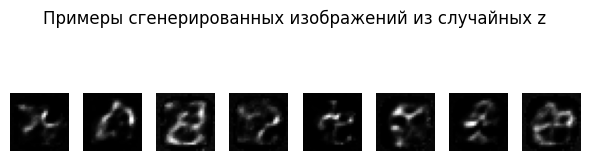

In [13]:
model.eval()
n_samples = 8

# сэмплируем z из N(0, 1)
z_random = torch.randn(n_samples, latent_dim).to(device)
with torch.no_grad():
    decoded = model.decoder(z_random)
    decoded = decoded.view(-1, 1, 28, 28).cpu()

plt.figure(figsize=(6, 2))
for i in range(n_samples):
    plt.subplot(1, n_samples, i + 1)
    plt.imshow(decoded[i].squeeze(0), cmap="gray")
    plt.axis("off")
plt.suptitle("Примеры сгенерированных изображений из случайных z")
plt.tight_layout()
plt.show()

### Обсуждение качества генерации

Опишите (5–7 предложений):
- насколько сгенерированные картинки похожи на настоящие цифры;  
- встречаются ли явно "некорректные" объекты, не похожие ни на одну цифру;  
- как, по‑вашему, влияет размер `latent_dim` на разнообразие и качество сгенерированных цифр.


In [ ]:
gen_comment = """
1. Сгенерированные при размерности 16, картинки не похожи на настоящие цифры.
2. Да, почти все варианты не похожи на на одну цифру
3. При уменьшении размерности генерация будет улучшаться, при увеличении ухудшаться. 
Обусловлено это тем, что при уменьшении размерности кластеры располагаются ближе друг к другу, соответсвенно декодеру будет лучше разбирать обобщенные данные
"""
print(gen_comment)

ЗДЕСЬ ОПИШИТЕ КАЧЕСТВО СГЕНЕРИРОВАННЫХ ЦИФР.
ПРИВЕДИТЕ ПРИМЕРЫ СЛУЧАЕВ, КОГДА ЦИФРА ВЫГЛЯДИТ ОЧЕНЬ УБЕДИТЕЛЬНО,
И КОГДА СОВСЕМ НЕТ, И СФОРМУЛИРУЙТЕ СВОИ ГИПОТЕЗЫ ПО ПОВОДУ ПРИЧИН.


## 9. Задание для самостоятельных вариаций

В **своём** варианте лабораторной вы должны будете:

- попробовать **не меньше двух дополнительных** значений `latent_dim` (например, 2 и 64) и сравнить:  
  - динамику loss,  
  - качество реконструкций,  
  - вид латентного пространства;  
- изменить архитектуру (добавить слои, поменять размеры, попробовать другой activation на скрытых слоях) и кратко описать, что изменилось;  
- оформить итоговые выводы так, чтобы через полгода, открыв ноутбук, вы по нескольким абзацам **вспомнили весь ход экспериментов**.


In [2]:
final_summary = """
1. Размерность латентного пространства 2:
- Loss падал достаточно медленно, остановившись около 0.03
- Качество реконструкции получлось хуже, чем у других вариантов из-за близкого расположения кластеров.
- Кластеры, как упомниалось выше, были расположены близко друг к другу.
Размерность латентного пространства 64:
- Loss уменьшался по -экспоненциальной траектории, сошелсся и был равен к 15 эпохе 0.007.
- Качество реконструкции получилось самым лучшим.
"""
print(final_summary)


1. Размерность латентного пространства 2:
- Loss падал достаточно медленно, остановившись около 0.03
- Качество реконструкции получлось хуже, чем у других вариантов из-за близкого расположения кластеров.
- Кластеры, как упомниалось выше, были расположены близко друг к другу.
Размерность латентного пространства 64:
- Loss уменьшался по -экспоненциальной траектории, сошелсся и был равен к 15 эпохе 0.007.
- Качество реконструкции получилось самым лучшим.

